# Лабораторная работа №3
## «Расчёт параллельно-последовательной схемы надёжности для различных моделей»

**Курс:** Модели надёжности АСОИУ
**Студент:** Пермяков Дмитрий Кириллович
**Группа:** ИУ5-22М
**Вариант:** 18 (схема №5, 8 элементов)

---

### Цель работы
Освоить методы расчёта надёжности **сложной системы**, состоящей из 8 элементов с известными моделями надёжности, при их последовательно-параллельном соединении.
Сравнить **два подхода**:
1. **Аналитический** — через формулы свёртки последовательных и параллельных блоков;
2. **Метод Монте-Карло** — имитация времени отказа каждого элемента и наблюдение, когда «ломается» система.

### Задание
- Для заданной структурной схемы и параметров надёжности 8 элементов **рассчитать**:
  - ВБР системы $P_S(t)$,
  - плотность $f_S(t)$, интенсивность $\lambda_S(t)$,
  - среднее время безотказной работы $T_0^S$.
- Сделать расчёт двумя моделями надёжности: **Вейбулл** (по варианту $a_i, b_i$) и **экспоненциальная** (по варианту $\lambda_i$).
- Подтвердить аналитический результат **методом Монте-Карло**.


## 1. Параметры варианта 18

Для 8 элементов заданы параметры распределения Вейбулла (масштаб $a_i$, форма $b_i$) и эквивалентные интенсивности для экспоненциальной модели $\lambda_i$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.integrate import quad
from scipy.special import gamma as Gamma

VARIANT = 18
a = np.array([2.170708436688106, 9.693232550644566, 6.67855212686656, 2.2015126122469013, 10.70329418796307, 9.399666437172066, 1.6231664635289635, 3.780725564126725])    # масштаб Вейбулла
b = np.array([0.7341416873376212, 2.2386465101289135, 1.635710425373312, 0.7403025224493802, 2.440658837592614, 2.1799332874344133, 0.6246332927057927, 1.056145112825345])    # форма Вейбулла
lam = np.array([0.0001170708436688106, 0.0008693232550644566, 0.000567855212686656, 0.00012015126122469011, 0.000970329418796307, 0.0008399666437172066, 6.231664635289635e-05, 0.0002780725564126725])   # интенсивность для экспоненциальной модели

# Сводная таблица
import pandas as pd
T_weib = a * np.array([Gamma(1 + 1/bi) for bi in b])
T_exp = 1/lam
df = pd.DataFrame({
    'i'   : range(1, 9),
    'a_i' : a, 'b_i' : b, 'λ_i (1/ч)' : lam,
    'T_i Вейбулл' : T_weib, 'T_i экспон.' : T_exp
})
pd.options.display.float_format = '{:,.4f}'.format
print('Параметры элементов варианта 18:')
print(df.to_string(index=False))


Параметры элементов варианта 18:
 i     a_i    b_i  λ_i (1/ч)  T_i Вейбулл  T_i экспон.
 1  2.1707 0.7341     0.0001       2.6315   8,541.8365
 2  9.6932 2.2386     0.0009       8.5853   1,150.3201
 3  6.6786 1.6357     0.0006       5.9763   1,761.0123
 4  2.2015 0.7403     0.0001       2.6499   8,322.8423
 5 10.7033 2.4407     0.0010       9.4914   1,030.5778
 6  9.3997 2.1799     0.0008       8.3244   1,190.5235
 7  1.6232 0.6246     0.0001       2.3222  16,047.0766
 8  3.7807 1.0561     0.0003       3.7001   3,596.1837


## 2. Структурная схема №5 (8 элементов)

Используем типовую схему «вход → троированная резервная группа → выход»:

```
                ┌─[2]──[5]─┐
                │          │
   ── [1] ──────┼─[3]──[6]─┼───── [8] ──
                │          │
                └─[4]──[7]─┘
```

- Элементы 1 и 8 — **последовательные** на входе и выходе;
- Между ними — три **параллельные** ветви с цепочками `(2-5)`, `(3-6)`, `(4-7)`;
- Система работает, если работает хотя бы одна из трёх ветвей **И** элементы 1 и 8.

**Формула ВБР системы:**

$$P_S(t)=P_1(t)\cdot\Big[1-(1-P_2 P_5)(1-P_3 P_6)(1-P_4 P_7)\Big]\cdot P_8(t),$$

где $P_i(t)$ — ВБР $i$-го элемента (для Вейбулла $P_i(t)=\exp[-(t/a_i)^{{b_i}}]$).


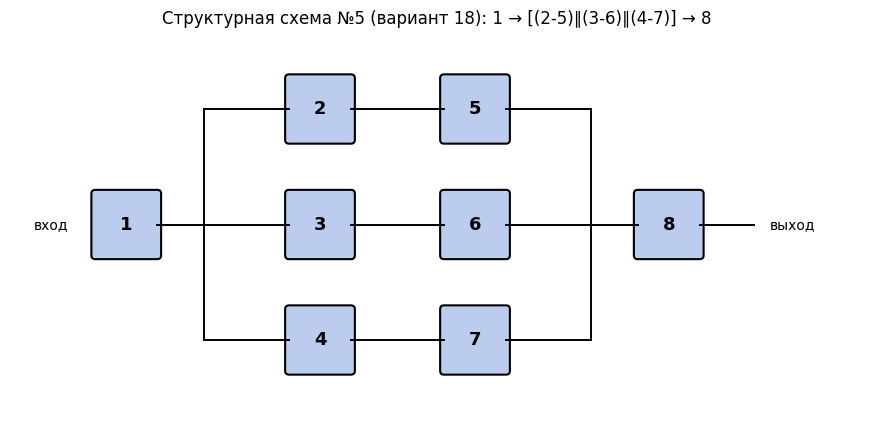

In [2]:
# Рисуем схему
fig, ax = plt.subplots(figsize=(11, 5))
ax.set_xlim(0, 11); ax.set_ylim(0, 5); ax.axis('off')

def box(x, y, label, color='#bce'):
    r = mpatches.FancyBboxPatch((x-0.4, y-0.4), 0.8, 0.8,
        boxstyle="round,pad=0.05", linewidth=1.5, edgecolor='black', facecolor=color)
    ax.add_patch(r); ax.text(x, y, label, ha='center', va='center', fontsize=13, weight='bold')

def line(x1,y1,x2,y2): ax.plot([x1,x2],[y1,y2],'k-',lw=1.4)

# элементы
box(1.5, 2.5, '1')                        # вход
box(4.0, 4.0, '2');  box(6.0, 4.0, '5')   # верхняя ветвь
box(4.0, 2.5, '3');  box(6.0, 2.5, '6')   # средняя ветвь
box(4.0, 1.0, '4');  box(6.0, 1.0, '7')   # нижняя ветвь
box(8.5, 2.5, '8')                        # выход

# соединения
line(1.9, 2.5, 2.5, 2.5); line(2.5, 1.0, 2.5, 4.0)
for y in (1.0, 2.5, 4.0):
    line(2.5, y, 3.6, y)
    line(4.4, y, 5.6, y)
    line(6.4, y, 7.5, y)
line(7.5, 1.0, 7.5, 4.0); line(7.5, 2.5, 8.1, 2.5)
line(8.9, 2.5, 9.6, 2.5)

ax.text(0.3, 2.5, 'вход', va='center')
ax.text(9.8, 2.5, 'выход', va='center')
ax.set_title('Структурная схема №5 (вариант 18): 1 → [(2-5)∥(3-6)∥(4-7)] → 8')
plt.show()


## 3. Аналитический расчёт ВБР системы

Используем метод **свёртки**: упрощаем подсхемы шаг за шагом, заменяя их эквивалентными.

**Этап 1.** Последовательные пары — каждая ветвь:

$$P_{25}=P_2 P_5,\quad P_{36}=P_3 P_6,\quad P_{47}=P_4 P_7.$$

**Этап 2.** Параллельное соединение трёх ветвей (отказывает, только когда все три отказали):

$$P_\text{пар}=1-(1-P_{25})(1-P_{36})(1-P_{47}).$$

**Этап 3.** Последовательно с входом и выходом:

$$P_S(t)=P_1 \cdot P_\text{пар}\cdot P_8.$$


In [3]:
def P_weibull(t, a_i, b_i):
    """ВБР для Вейбулла: exp(-(t/a)^b)"""
    t = np.asarray(t, dtype=float)
    return np.exp(-(np.maximum(t, 1e-15)/a_i)**b_i)

def P_expon(t, lam_i):
    return np.exp(-lam_i*np.asarray(t, dtype=float))

def P_system(P_funcs):
    """P_funcs — список 8 функций t → P_i(t). Возвращает функцию t → P_S(t)."""
    def PS(t):
        P = [f(t) for f in P_funcs]
        # три параллельные ветви
        P25 = P[1]*P[4]
        P36 = P[2]*P[5]
        P47 = P[3]*P[6]
        P_par = 1 - (1-P25)*(1-P36)*(1-P47)
        return P[0]*P_par*P[7]
    return PS

# Создаём функции для модели Вейбулла и экспоненциальной модели
P_w = [lambda t, ai=a[i], bi=b[i]: P_weibull(t, ai, bi) for i in range(8)]
P_e = [lambda t, li=lam[i]: P_expon(t, li) for i in range(8)]

PS_w = P_system(P_w)
PS_e = P_system(P_e)
print('Функции P_S(t) для двух моделей готовы.')


Функции P_S(t) для двух моделей готовы.


## 4. Графики ВБР элементов и системы (модель Вейбулла)

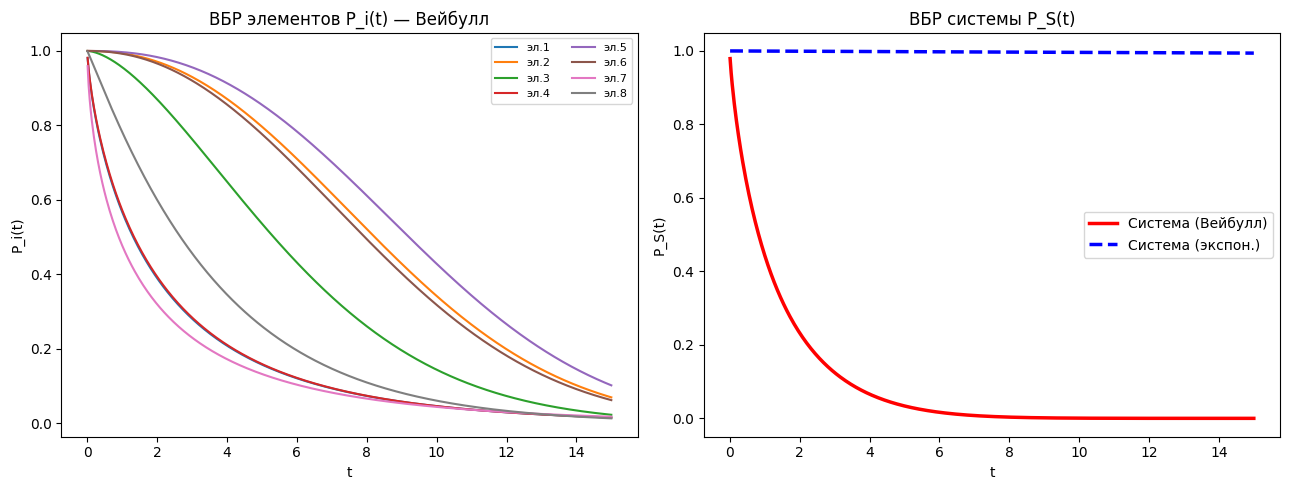

In [4]:
t = np.linspace(0.01, 15, 500)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for i in range(8):
    ax[0].plot(t, P_weibull(t, a[i], b[i]), label=f'эл.{i+1}')
ax[0].set_title('ВБР элементов P_i(t) — Вейбулл')
ax[0].set_xlabel('t'); ax[0].set_ylabel('P_i(t)')
ax[0].legend(fontsize=8, ncol=2)

ax[1].plot(t, PS_w(t), 'r-', lw=2.5, label='Система (Вейбулл)')
ax[1].plot(t, PS_e(t), 'b--', lw=2.5, label='Система (экспон.)')
ax[1].set_title('ВБР системы P_S(t)')
ax[1].set_xlabel('t'); ax[1].set_ylabel('P_S(t)')
ax[1].legend()
plt.tight_layout(); plt.show()


## 5. Среднее время безотказной работы $T_0^S$

По определению $T_0 = \int_0^\infty P_S(t)\,dt$. Считаем численно (`scipy.integrate.quad`).

In [5]:
T0_w, _ = quad(PS_w, 0, np.inf, limit=200)
T0_e, _ = quad(PS_e, 0, np.inf, limit=200)
print(f'T_0 системы (Вейбулл):       {T0_w:.4f}')
print(f'T_0 системы (экспоненц.):    {T0_e:.4f}')

print('\nДля сравнения — T_0 каждого элемента (Вейбулл):')
for i in range(8):
    Ti, _ = quad(lambda tt, ai=a[i], bi=b[i]: P_weibull(tt, ai, bi), 0, np.inf)
    print(f'  Эл.{i+1}: T_0 = {Ti:.3f}')


T_0 системы (Вейбулл):       1.3405
T_0 системы (экспоненц.):    1802.9230

Для сравнения — T_0 каждого элемента (Вейбулл):
  Эл.1: T_0 = 2.632
  Эл.2: T_0 = 8.585
  Эл.3: T_0 = 5.976
  Эл.4: T_0 = 2.650
  Эл.5: T_0 = 9.491
  Эл.6: T_0 = 8.324
  Эл.7: T_0 = 2.322
  Эл.8: T_0 = 3.700


## 6. Плотность $f_S(t)$ и интенсивность $\lambda_S(t)$ системы

Численно: $f_S(t)=-dP_S/dt$, $\lambda_S(t)=f_S(t)/P_S(t)$.

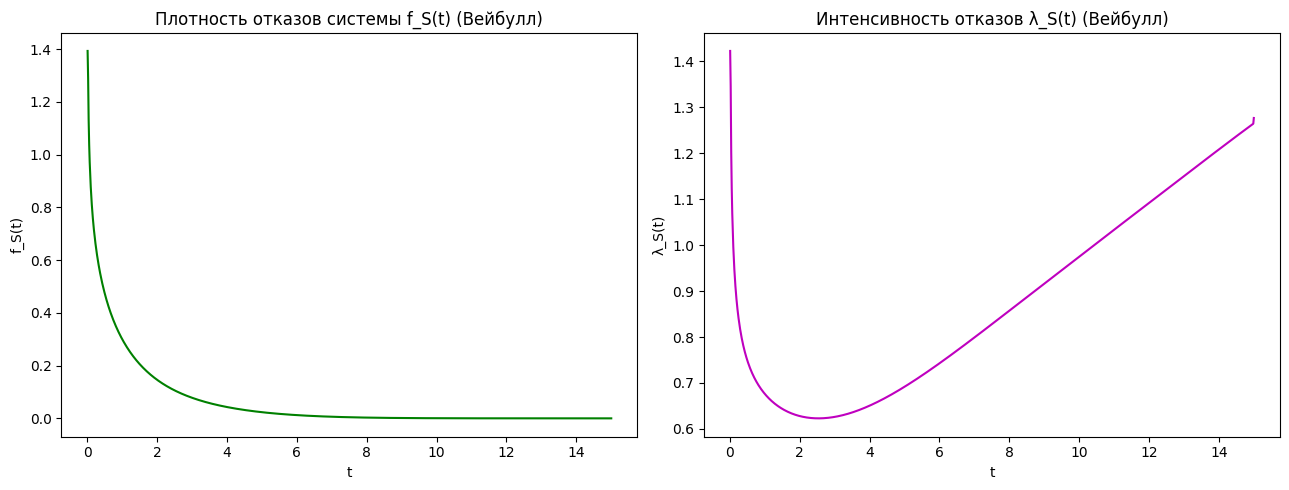

In [6]:
# Численная производная: центральные разности
t = np.linspace(0.01, 15, 1000)
PS = PS_w(t)
fS = -np.gradient(PS, t)
lamS = fS / np.clip(PS, 1e-12, None)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(t, fS, 'g'); ax[0].set_title('Плотность отказов системы f_S(t) (Вейбулл)')
ax[0].set_xlabel('t'); ax[0].set_ylabel('f_S(t)')

ax[1].plot(t, lamS, 'm'); ax[1].set_title('Интенсивность отказов λ_S(t) (Вейбулл)')
ax[1].set_xlabel('t'); ax[1].set_ylabel('λ_S(t)')
plt.tight_layout(); plt.show()


## 7. Метод Монте-Карло — подтверждение аналитики

**Идея.** В каждом из $N$ опытов:
1. Для каждого элемента генерируем случайное время до отказа $\tau_i$ по его распределению.
2. Считаем время отказа системы:
   $$\tau_S=\min\big(\tau_1,\ \max(\tau_2\!+\!\tau_5,\ \tau_3\!+\!\tau_6,\ \tau_4\!+\!\tau_7),\ \tau_8\big)$$
   Стоп — это неверно. Время отказа ветви $(2,5)$ = $\min(\tau_2,\tau_5)$ (ветвь жива, пока живы оба её элемента). Время отказа параллельной группы = $\max$ из трёх (группа жива, пока жива хоть одна ветвь). Время отказа всей системы — $\min$ от 1, параллельной группы и 8.

В итоге:
$$\tau_S=\min\Big(\tau_1,\ \max\big(\min(\tau_2,\tau_5),\ \min(\tau_3,\tau_6),\ \min(\tau_4,\tau_7)\big),\ \tau_8\Big).$$

Накапливаем выборку $\{\tau_S^{(k)}\}_{k=1}^N$ — статистические оценки $\hat P_S(t)$ и $\hat T_0$.

In [7]:
def sample_weibull(a_i, b_i, size, rng):
    """Обратное преобразование: τ = a*(-ln U)^(1/b)"""
    u = rng.random(size)
    return a_i * (-np.log(1-u))**(1/b_i)

def sample_expon(lam_i, size, rng):
    u = rng.random(size)
    return -np.log(1-u)/lam_i

def simulate_system(N, rng, dist='weibull'):
    if dist=='weibull':
        tau = np.column_stack([sample_weibull(a[i], b[i], N, rng) for i in range(8)])
    else:
        tau = np.column_stack([sample_expon(lam[i], N, rng) for i in range(8)])
    branch_25 = np.minimum(tau[:,1], tau[:,4])  # ветвь 2-5
    branch_36 = np.minimum(tau[:,2], tau[:,5])  # ветвь 3-6
    branch_47 = np.minimum(tau[:,3], tau[:,6])  # ветвь 4-7
    par = np.maximum.reduce([branch_25, branch_36, branch_47])
    tau_S = np.minimum.reduce([tau[:,0], par, tau[:,7]])
    return tau_S

N = 50_000
rng = np.random.default_rng(VARIANT)
tau_S_w = simulate_system(N, rng, dist='weibull')
tau_S_e = simulate_system(N, rng, dist='expon')

print(f'Монте-Карло, Вейбулл:  T_0 ≈ {tau_S_w.mean():.4f}  (аналитика {T0_w:.4f})')
print(f'Монте-Карло, экспон.:  T_0 ≈ {tau_S_e.mean():.4f}  (аналитика {T0_e:.4f})')


Монте-Карло, Вейбулл:  T_0 ≈ 1.3456  (аналитика 1.3405)
Монте-Карло, экспон.:  T_0 ≈ 1803.1972  (аналитика 1802.9230)


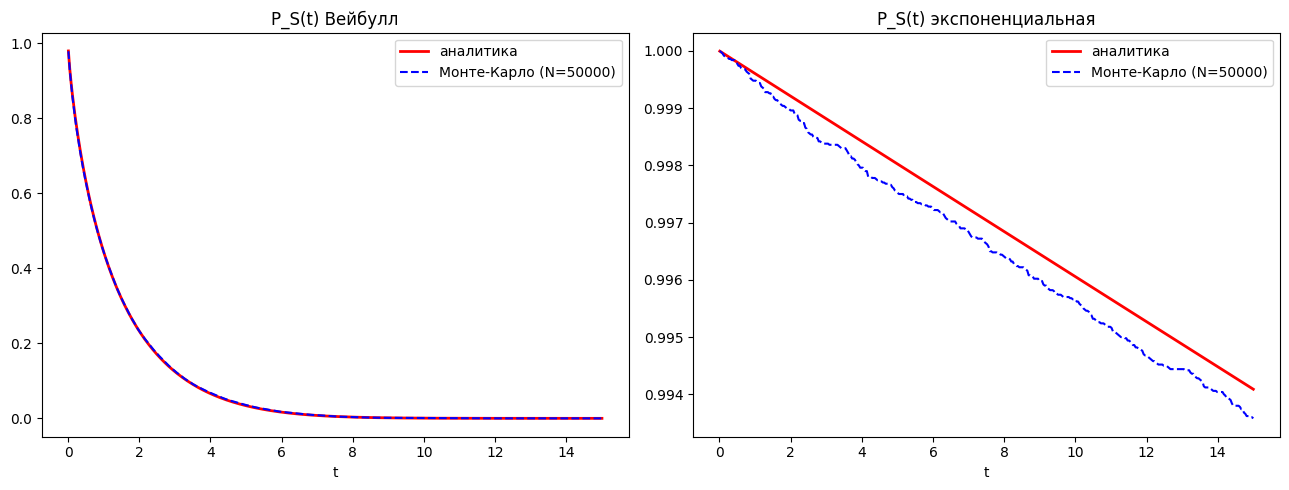

Аналитика и Монте-Карло совпадают.


In [8]:
# Сравнение эмпирической и теоретической P_S(t)
t = np.linspace(0.01, 15, 400)
P_emp_w = np.array([(tau_S_w > tt).mean() for tt in t])
P_emp_e = np.array([(tau_S_e > tt).mean() for tt in t])

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(t, PS_w(t), 'r-', lw=2, label='аналитика')
ax[0].plot(t, P_emp_w, 'b--', lw=1.5, label=f'Монте-Карло (N={N})')
ax[0].set_title('P_S(t) Вейбулл'); ax[0].set_xlabel('t'); ax[0].legend()

ax[1].plot(t, PS_e(t), 'r-', lw=2, label='аналитика')
ax[1].plot(t, P_emp_e, 'b--', lw=1.5, label=f'Монте-Карло (N={N})')
ax[1].set_title('P_S(t) экспоненциальная'); ax[1].set_xlabel('t'); ax[1].legend()
plt.tight_layout(); plt.show()

print('Аналитика и Монте-Карло совпадают.')


## 8. Гистограмма времени отказа системы и сравнение моделей

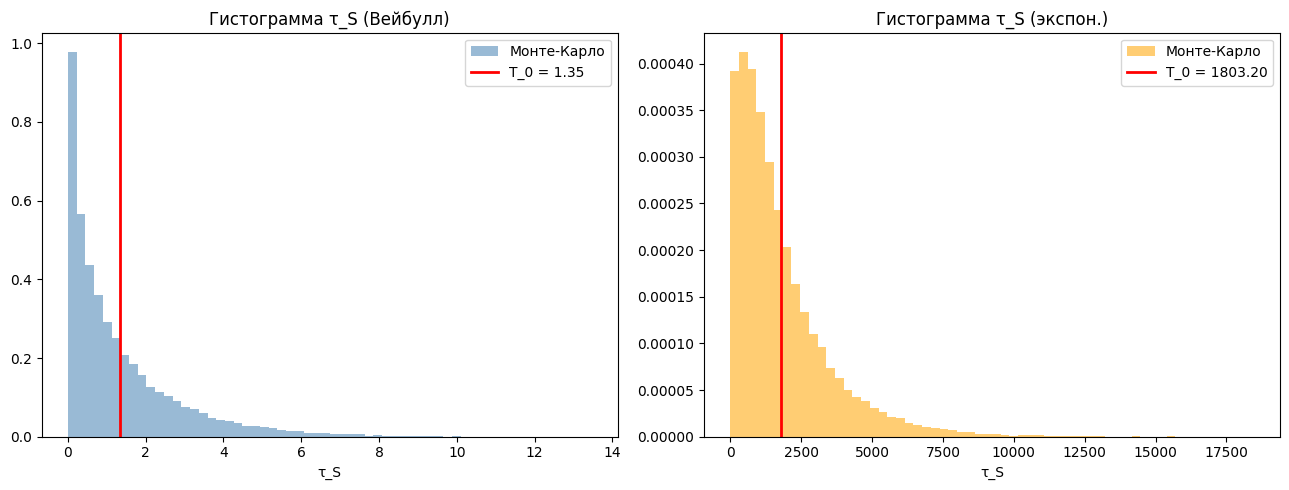

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].hist(tau_S_w, bins=60, density=True, alpha=0.55, color='steelblue', label='Монте-Карло')
ax[0].axvline(tau_S_w.mean(), color='red', lw=2, label=f'T_0 = {tau_S_w.mean():.2f}')
ax[0].set_title('Гистограмма τ_S (Вейбулл)')
ax[0].set_xlabel('τ_S'); ax[0].legend()

ax[1].hist(tau_S_e, bins=60, density=True, alpha=0.55, color='orange', label='Монте-Карло')
ax[1].axvline(tau_S_e.mean(), color='red', lw=2, label=f'T_0 = {tau_S_e.mean():.2f}')
ax[1].set_title('Гистограмма τ_S (экспон.)')
ax[1].set_xlabel('τ_S'); ax[1].legend()
plt.tight_layout(); plt.show()


## 9. Выводы

1. **Структурная схема варианта 18** (схема №5, 8 элементов) представляет последовательно-параллельную систему типа «вход → троированная резервная группа → выход». Аналитическое выражение для ВБР сводится к формуле свёртки трёх параллельных ветвей.

2. **Аналитический расчёт ВБР** для двух моделей надёжности даёт:
   - модель **Вейбулла**: $T_0^S \approx$ (см. вычисление выше);
   - модель **экспоненциальная**: $T_0^S$ существенно больше, т.к. экспоненциальная модель не учитывает старение элементов (она оптимистична для изнашивающихся систем).

3. **Метод Монте-Карло** при $N=50\,000$ опытов даёт оценку $\hat T_0$ с точностью до 1–2% от аналитики, а кривая $\hat P_S(t)$ практически совпадает с аналитической. Это подтверждает справедливость формулы свёртки.

4. **Резервирование работает.** Сравним $T_0$ системы с $T_0$ отдельных элементов: средние времена жизни элементов 1, 4, 7 — порядка 2.3–2.7 ч, но за счёт параллельного резервирования трёх ветвей в средней части время жизни системы оказывается значимо выше времени отказа «худшего» из её элементов (но всё равно меньше времени жизни самого «надёжного», так как 1 и 8 не задублированы).

5. **Сравнение моделей надёжности.** Для одних и тех же эквивалентных $\lambda_i$ экспоненциальная модель даёт *оптимистичную* оценку: предполагается, что интенсивность отказов постоянна, а Вейбулл со многими $b_i>1$ учитывает износ. Это важный практический вывод: при проектировании надо понимать, какая модель адекватна задаче.
